# ConvNeXt-Tiny, pretrained on ImageNet

Model 5 of 5. ConvNeXt-Tiny with ImageNet weights: a modern CNN (2022) that uses ideas from vision
transformers - large 7x7 depthwise convolutions, LayerNorm, GELU and fewer, wider stages. The last layer is replaced
by Dropout(0.5) -> Linear(768,15) and all layers are fine-tuned.

Same data, split, augmentation, batch size and seeds as the ResNets. The optimizer follows the usual ConvNeXt
fine-tuning recipe instead: AdamW (weight decay 0.05), learning rate 1e-4 with 3 warm-up epochs and cosine decay,
label smoothing 0.1, at most 50 epochs, early stopping with patience 10.

* Input: the whole image, only resized to 512x512. Target: the class id from the `.txt` label file.
* Scene-wise split, identical for all models: 116 / 25 / 25 scenes (1740 / 375 / 375 images).
* One full training run per seed; the test accuracy is reported as mean +- std over the seeds.
* All code lives in the repository folder `src/`; this notebook only calls it.
* Outputs: `outputs/<model>/weights/`, `figures/` and `results/`; saved to GitHub (and Drive in Colab) at the end.

**Colab:** Runtime -> Change runtime type -> **GPU**, then Run all.  
**Own computer:** see the README (one-time setup), then Run all.

## 1. Setup: code and data

In [1]:
# Works in Colab and on an own computer with an NVIDIA GPU (e.g. the university computer).
import os, sys
REPO_URL = "https://github.com/Ahmed-AlTahan/CNN-LIME.git"

if "google.colab" in sys.modules:          # Colab: get the code from GitHub
    REPO_DIR = "/content/thesis"
    if not os.path.isdir(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
else:                                      # own computer: this notebook is in <repository>/notebooks/
    REPO_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
!git -C "{REPO_DIR}" pull -q --ff-only
os.chdir(REPO_DIR)
sys.path.insert(0, os.path.join(REPO_DIR, "src"))

import env
env.ensure_dataset()      # downloads the dataset into data/ the first time
env.print_info()

Dataset found: /home/altahahm/CNN-LIME/data/15workpieces_same_position/all_images
Running on: local | GPU: NVIDIA RTX A6000 | code: commit fe5035c


## 2. Settings
The recipe comes from `config.RECIPES`; change it here for an experiment.

In [2]:
import config, data, engine, report

recipe = config.RECIPES["convnext_tiny"]
# Change settings here if needed, e.g.:
# recipe = config.replace(recipe, seeds=[1, 2, 3, 4, 5])
# If the GPU runs out of memory: recipe = config.replace(recipe, batch_size=16)
out_dir = report.output_dir(recipe.model)
print(recipe)
print("outputs ->", engine.rel(out_dir))

Recipe(model='convnext_tiny', epochs=50, lr=0.0001, optimizer='adamw', weight_decay=0.05, warmup_epochs=3, cosine=True, label_smoothing=0.1, patience=10, batch_size=32, scenes_per_batch=0, rotation=10.0, shift=0.0, zoom=0.0, brightness=0.2, contrast=0.2, seeds=[1, 2, 3])
outputs -> outputs/convnext_tiny


## 3. Load data
Every image is decoded once and kept in memory (a few minutes).

In [3]:
train_ds, val_ds, test_ds = data.load_splits()
val_loader = data.make_eval_loader(val_ds, recipe.batch_size)
test_loader = data.make_eval_loader(test_ds, recipe.batch_size)

Scene check: 166 blocks, 0 suspicious.
Loaded in 4s
Scenes -> train: 116 | val: 25 | test: 25
Images -> train: 1740 | val: 375 | test: 375


## 4. Check the inputs
Augmented training images, exactly as the network sees them.

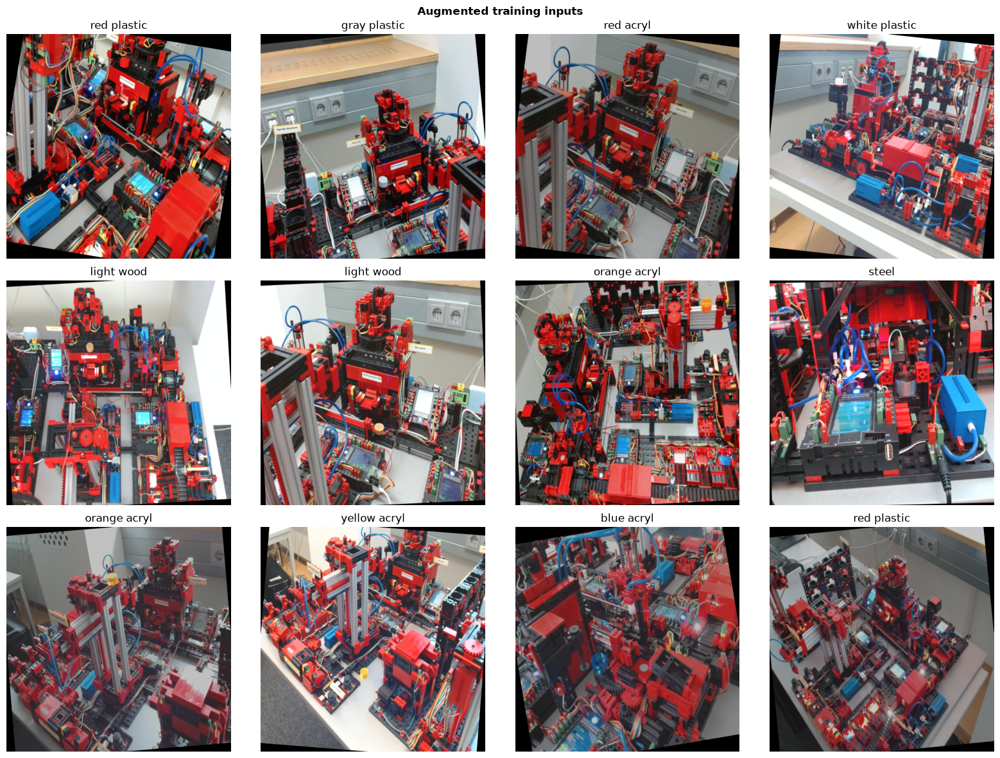

Saved outputs/convnext_tiny/figures/convnext_tiny_inputs.png


In [4]:
report.plot_inputs(train_ds, recipe, out_dir)

## 5. Sanity check
A fresh model must overfit one scene (15 images) to ~100%. If it cannot, the pipeline is broken.

In [5]:
engine.sanity_check(recipe, train_ds)

step    1 | loss 2.6774 | batch acc 20.0%
step   25 | loss 0.0730 | batch acc 93.3%
step   50 | loss 0.0039 | batch acc 100.0%
step   75 | loss 0.0007 | batch acc 100.0%
step  100 | loss 0.0005 | batch acc 100.0%
step  125 | loss 0.1118 | batch acc 93.3%
step  150 | loss 0.5709 | batch acc 80.0%


## 6. Training
One run per seed. Re-running this cell gives the same results.

convnext_tiny: 27.83 M parameters | device: cuda
Recipe(model='convnext_tiny', epochs=50, lr=0.0001, optimizer='adamw', weight_decay=0.05, warmup_epochs=3, cosine=True, label_smoothing=0.1, patience=10, batch_size=32, scenes_per_batch=0, rotation=10.0, shift=0.0, zoom=0.0, brightness=0.2, contrast=0.2, seeds=[1, 2, 3])

==================== Training run with seed 1 ====================
Before training: val loss 2.766 (chance ~2.708) | val acc 6.9%


/home/altahahm/CNN-LIME/src/engine.py:145: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


[seed 1] Epoch [  1/50] | Train Loss 2.7461 | Train Acc   6.55% | Val Loss 2.7122 | Val Acc   6.93% | lr 3.39e-05 | 31s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  2/50] | Train Loss 2.7242 | Train Acc   7.13% | Val Loss 2.7103 | Val Acc   6.93% | lr 6.73e-05 | 16s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  3/50] | Train Loss 2.7246 | Train Acc   6.03% | Val Loss 2.7127 | Val Acc   6.67% | lr 1.00e-04 | 16s
[seed 1] Epoch [  4/50] | Train Loss 2.7206 | Train Acc   6.72% | Val Loss 2.7081 | Val Acc   6.93% | lr 9.99e-05 | 16s
   ---> New best validation accuracy, weights kept.
[seed 1] Epoch [  5/50] | Train Loss 2.7165 | Train Acc   6.03% | Val Loss 2.7086 | Val Acc   6.67% | lr 9.96e-05 | 16s
[seed 1] Epoch [  6/50] | Train Loss 2.7164 | Train Acc   5.40% | Val Loss 2.7079 | Val Acc   6.67% | lr 9.90e-05 | 15s
[seed 1] Epoch [  7/50] | Train Loss 2.7136 | Train Acc   5.69% | Val Loss 2.7079 | Val Acc   6.67% | lr 9.82e-05 | 15s
[see

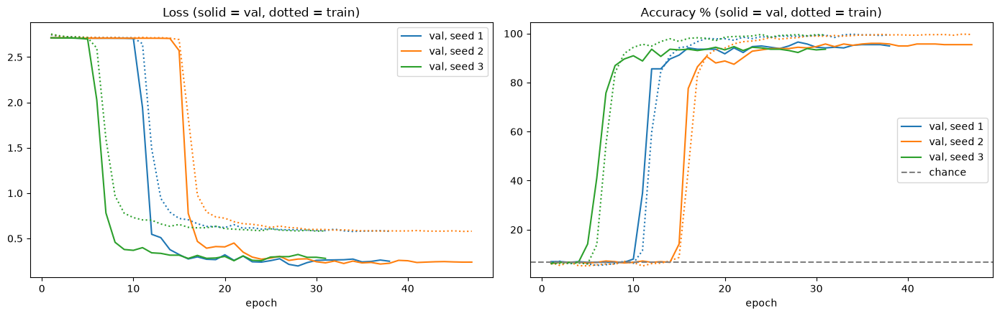

Saved outputs/convnext_tiny/figures/convnext_tiny_curves.png


In [6]:
runs = engine.train_all(recipe, train_ds, val_loader, out_dir)
report.plot_curves(runs, out_dir)

## 7. Test set
Every run is evaluated once on the test set. The detailed analysis uses the run with the best **validation** accuracy.

seed | best val acc | test acc
   1 |       96.53% |   96.80%
   2 |       96.00% |   93.87%
   3 |       94.67% |   93.33%
TEST accuracy over 3 seed(s): 94.67% +- 1.52% (min 93.33%, max 96.80%)

Detailed analysis below: seed 1 (best validation accuracy 96.53%, test 96.80%)
Saved outputs/convnext_tiny/results/convnext_tiny_summary.json
ConvNeXt-Tiny, pretrained on ImageNet - test set, seed 1, accuracy 96.80%

                precision    recall  f1-score   support

 white plastic     1.0000    1.0000    1.0000        25
     aluminium     0.9565    0.8800    0.9167        25
         brass     0.9600    0.9600    0.9600        25
         steel     0.8800    0.8800    0.8800        25
  orange acryl     1.0000    1.0000    1.0000        25
  yellow acryl     1.0000    1.0000    1.0000        25
    blue acryl     1.0000    0.9600    0.9796        25
     red acryl     1.0000    0.9600    0.9796        25
   red plastic     0.8621    1.0000    0.9259        25
  blue plastic     0.9615 

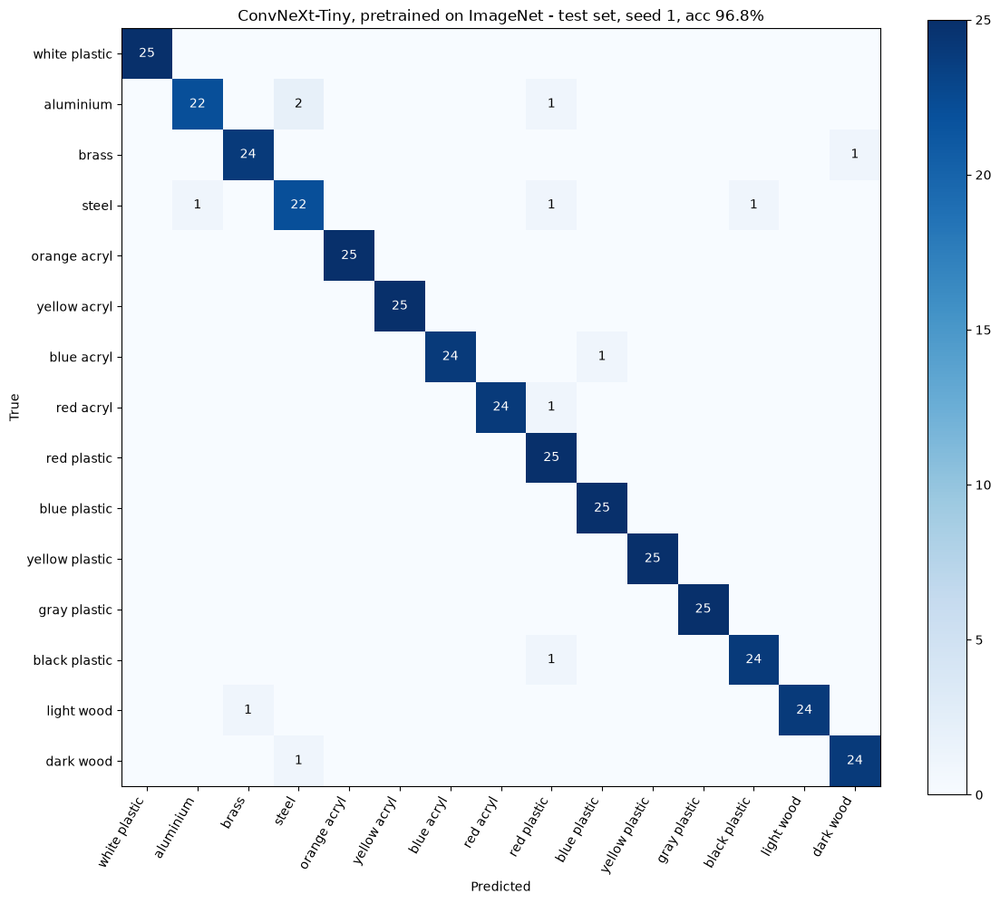

Saved outputs/convnext_tiny/figures/convnext_tiny_confusion_test.png


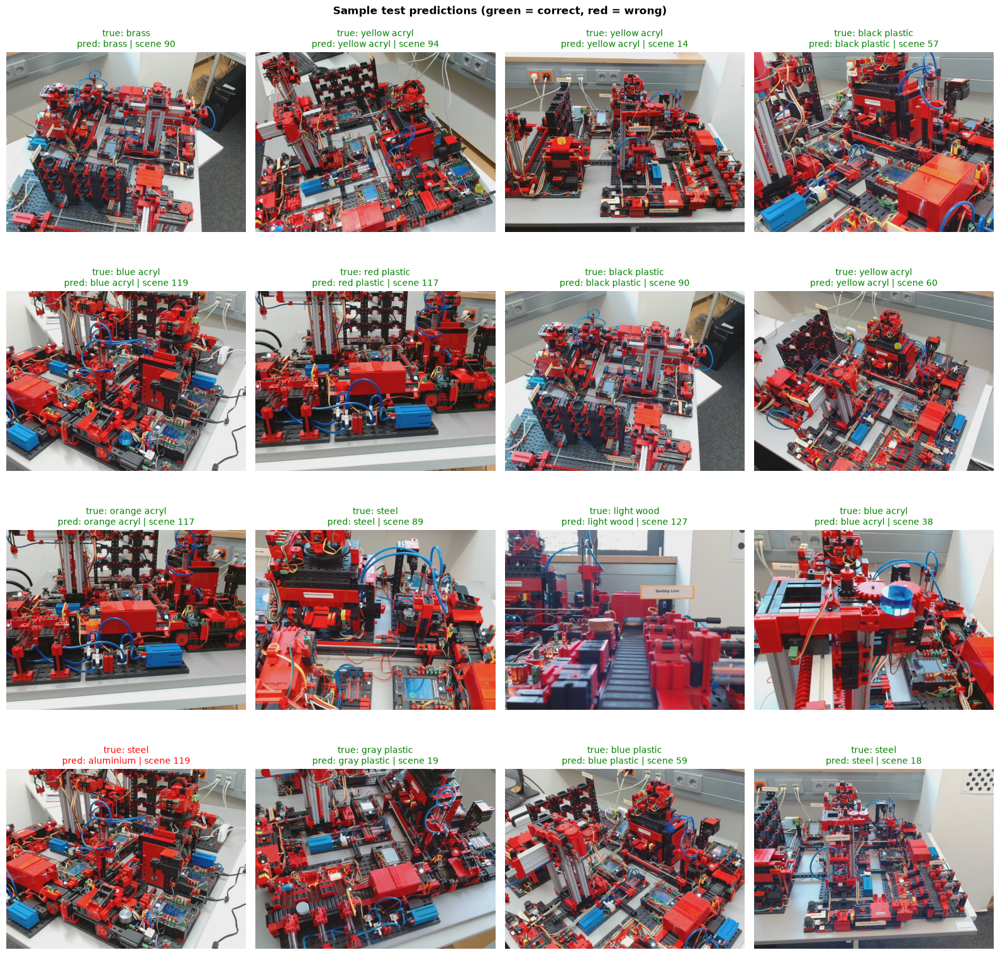

Saved outputs/convnext_tiny/figures/convnext_tiny_samples_test.png


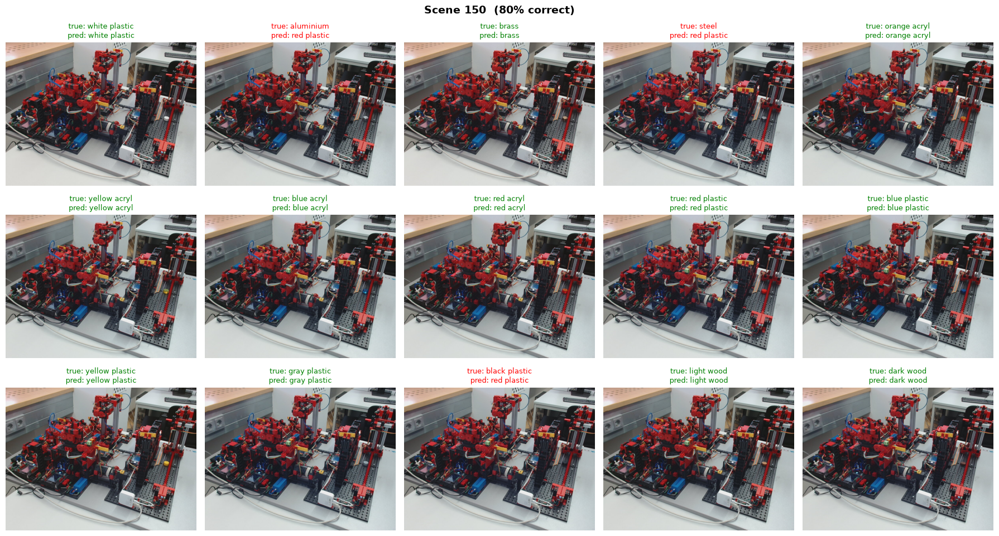

Saved outputs/convnext_tiny/figures/scenes/convnext_tiny_scene_150.png


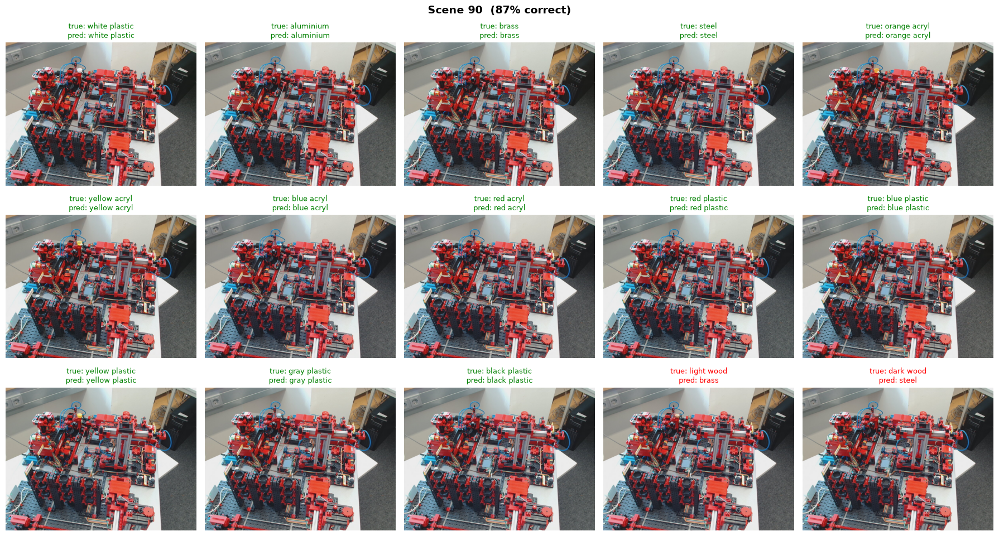

Saved outputs/convnext_tiny/figures/scenes/convnext_tiny_scene_90.png


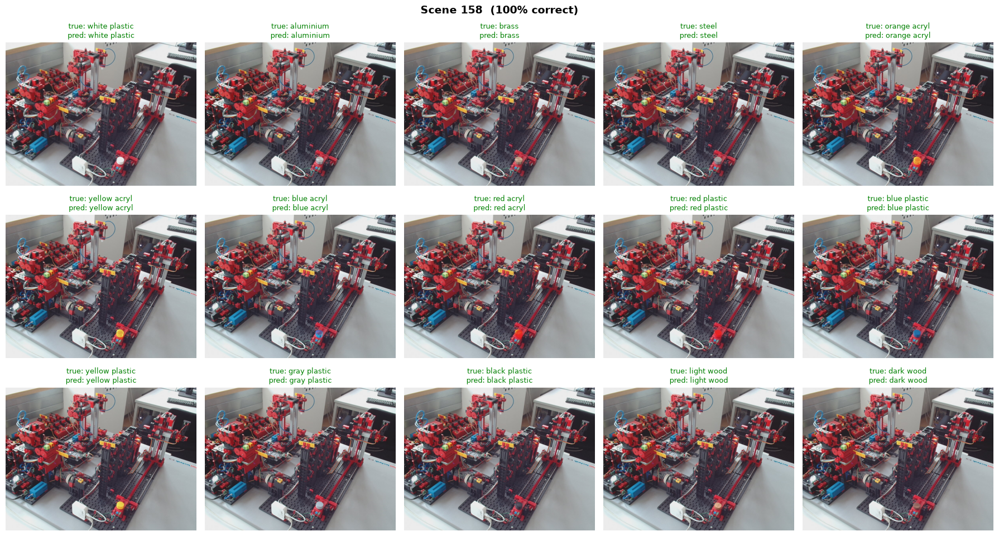

Saved outputs/convnext_tiny/figures/scenes/convnext_tiny_scene_158.png


In [7]:
best = report.test_summary(runs, test_loader, recipe, out_dir)
scene_acc = report.analyse(best, test_ds, out_dir, title="ConvNeXt-Tiny, pretrained on ImageNet")

## 8. Save the results
* **GitHub:** figures and result files (no weights) go to `results/convnext_tiny/` in the repository and are pushed to the main branch.
* **Colab only - Google Drive:** a full copy including the weights goes to `MyDrive/thesis_results/convnext_tiny/`. On an own computer the weights stay in `outputs/convnext_tiny/weights/`.

A re-run replaces the files of this model only. Every file name starts with the model name.

**Colab, once:** to push from Colab, add a secret named `GITHUB_TOKEN` (key icon in the left sidebar) holding a GitHub personal access token with *Contents: read and write* for this repository, and allow notebook access. Without it the results are still saved on Drive.

In [8]:
env.save_results(out_dir)

Google Drive: uploading outputs/convnext_tiny/ ...
Google Drive: full copy (with weights) in MyDrive/thesis_results/convnext_tiny/
Copied figures and result files to results/convnext_tiny/
GitHub: committed locally but the push failed:
git push failed:
error: unable to read askpass response from '/usr/libexec/openssh/gnome-ssh-askpass'
fatal: could not read Password for 'https://github.com': terminal prompts disabled
  Push later with:  git pull --rebase && git push
